# Quinta Lista de Ejercicios: Selección de Variables y Generalización
**Universidad El Bosque - Programa de Matemáticas y Estadística**  
**Introducción al Machine Learning (2026-2)**

---
## Preparación y Partición de los Datos

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from lista5 import (
    cargar_hitters,
    particionar_datos,
    riesgo_cuadratico,
    ajustar_regresion,
    evaluar_modelo,
    correlaciones_entrenamiento,
    pruebas_t_regresion_completa,
    seleccion_hacia_adelante,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid")

# Carga y partición en dos etapas con random_state=31
df = cargar_hitters()
X_train, X_val, X_test, y_train, y_val, y_test = particionar_datos(df, target="Salary", random_state=31)

todas_las_variables = list(X_train.columns)
print(f"Total de observaciones: {len(df)} | Total predictoras: {len(todas_las_variables)}")
print(f"Tamaño Entrenamiento: {len(X_train)} | Validación: {len(X_val)} | Prueba: {len(X_test)}")

Total de observaciones: 263 | Total predictoras: 19
Tamaño Entrenamiento: 50 | Validación: 70 | Prueba: 143


## Ejercicio 1. Modelo completo
Ajuste una regresión lineal con las 19 variables.
- **(a)** Calcule el riesgo en entrenamiento y validación.
- **(b)** Registre ambos valores.

In [2]:
modelo_completo = ajustar_regresion(X_train, y_train, todas_las_variables)
eval_completo = evaluar_modelo(modelo_completo, todas_las_variables, X_train, y_train, X_val, y_val)

tabla_ej1 = pd.DataFrame([{
    "Modelo": "Modelo completo (19 variables)",
    "Num_Variables": len(todas_las_variables),
    "Riesgo_Entrenamiento": eval_completo["riesgo_train"],
    "Riesgo_Validacion": eval_completo["riesgo_val"]
}])
display(tabla_ej1)

,Modelo,Num_Variables,Riesgo_Entrenamiento,Riesgo_Validacion
0,Modelo completo (19 variables),19,"68,584.8164","320,423.1919"


**Respuesta Ejercicio 1:**
- **Riesgo de entrenamiento ($\hat{R}_{\text{train}}$):** `68,584.8164`
- **Riesgo de validación ($\hat{R}_{\text{val}}$):** `320,423.1919`

Se observa un fuerte sobreajuste (*overfitting*): al ajustar 19 parámetros más el intercepto con tan solo $n = 50$ observaciones de entrenamiento, el modelo logra un riesgo de entrenamiento bajo pero generaliza de forma deficiente en validación (el riesgo se multiplica por más de 4.6 veces).

## Ejercicio 2. Selección estadística de variables
- **(a)** Calcule la correlación de Pearson de cada variable con `Salary`, usando solo entrenamiento. Ordénelas por el valor absoluto de su correlación.
- **(b)** Ajuste una regresión con las siete variables de mayor correlación. Calcule los riesgos de entrenamiento y validación.
- **(c)** En la regresión completa, obtenga el valor $p$ de la prueba $t$ de cada coeficiente. Seleccione las variables con $p < 0.05$, ajuste una regresión con ellas y calcule ambos riesgos.
- **(d)** Reporte las variables seleccionadas por cada criterio y compare los riesgos de los modelos obtenidos.

### (a) Correlación de Pearson en entrenamiento y (b) Regresión con las 7 variables de mayor correlación

In [3]:
df_correlaciones = correlaciones_entrenamiento(X_train, y_train)
print("(a) Correlaciones de Pearson con Salary (ordenadas por |r| en entrenamiento):")
display(df_correlaciones)


vars_top7_corr = df_correlaciones.loc[:6, "Variable"].tolist()
modelo_corr7 = ajustar_regresion(X_train, y_train, vars_top7_corr)
eval_corr7 = evaluar_modelo(modelo_corr7, vars_top7_corr, X_train, y_train, X_val, y_val)

print(f"\n(b) Siete variables de mayor correlación: {vars_top7_corr}")
print(f"    Riesgo de entrenamiento: {eval_corr7['riesgo_train']:,.4f}")
print(f"    Riesgo de validación:    {eval_corr7['riesgo_val']:,.4f}")

(a) Correlaciones de Pearson con Salary (ordenadas por |r| en entrenamiento):


,Variable,Correlacion,Abs_Correlacion,p_valor_corr
0,CRBI,0.4333,0.4333,0.0017
1,CRuns,0.4252,0.4252,0.0021
2,CHmRun,0.4181,0.4181,0.0025
3,CHits,0.4165,0.4165,0.0026
4,CAtBat,0.3835,0.3835,0.0060
5,CWalks,0.2915,0.2915,0.0400
6,Years,0.2414,0.2414,0.0913
7,PutOuts,0.1926,0.1926,0.1801
8,HmRun,0.1833,0.1833,0.2025
9,RBI,0.1813,0.1813,0.2076



(b) Siete variables de mayor correlación: ['CRBI', 'CRuns', 'CHmRun', 'CHits', 'CAtBat', 'CWalks', 'Years']
    Riesgo de entrenamiento: 115,487.2485
    Riesgo de validación:    133,035.6122


### (c) Valores p de la prueba t en la regresión completa (solo con entrenamiento)

In [4]:
df_pruebas_t = pruebas_t_regresion_completa(X_train, y_train)
print("(c) Pruebas t de los coeficientes en la regresión completa:")
display(df_pruebas_t)

vars_pruebas_t = df_pruebas_t[df_pruebas_t["valor_p"] < 0.05]["Variable"].tolist()
modelo_pruebas_t = ajustar_regresion(X_train, y_train, vars_pruebas_t)
eval_pruebas_t = evaluar_modelo(modelo_pruebas_t, vars_pruebas_t, X_train, y_train, X_val, y_val)

print(f"\nVariables seleccionadas con p < 0.05 ({len(vars_pruebas_t)} variables): {vars_pruebas_t}")
print(f"    Riesgo de entrenamiento: {eval_pruebas_t['riesgo_train']:,.4f}")
print(f"    Riesgo de validación:    {eval_pruebas_t['riesgo_val']:,.4f}")

(c) Pruebas t de los coeficientes en la regresión completa:


,Variable,Coeficiente,Error_Estandar,Estadistico_t,valor_p
0,AtBat,-6.4584,2.1123,-3.0575,0.0047
1,Assists,2.2501,0.8671,2.5950,0.0145
2,CWalks,-2.5182,1.1633,-2.1648,0.0385
3,Runs,17.4928,9.4958,1.8422,0.0754
4,Errors,-28.1610,15.6520,-1.7992,0.0821
5,RBI,16.9727,10.0343,1.6915,0.1011
6,Years,-47.8583,36.5674,-1.3088,0.2005
7,CRuns,2.2719,2.4780,0.9168,0.3665
8,NewLeague,151.0570,191.9665,0.7869,0.4375
9,CHmRun,-4.8235,6.1764,-0.7810,0.4409



Variables seleccionadas con p < 0.05 (3 variables): ['AtBat', 'Assists', 'CWalks']
    Riesgo de entrenamiento: 161,221.3618
    Riesgo de validación:    140,085.1870


### (d) Comparación de modelos hasta el Ejercicio 2

In [5]:
tabla_ej2 = pd.DataFrame([
    {
        "Modelo": "Todas las variables (19)",
        "Num_Vars": len(todas_las_variables),
        "Variables_Seleccionadas": ", ".join(todas_las_variables),
        "Riesgo_Train": eval_completo["riesgo_train"],
        "Riesgo_Validacion": eval_completo["riesgo_val"],
    },
    {
        "Modelo": "Mayor correlación (Top 7)",
        "Num_Vars": len(vars_top7_corr),
        "Variables_Seleccionadas": ", ".join(vars_top7_corr),
        "Riesgo_Train": eval_corr7["riesgo_train"],
        "Riesgo_Validacion": eval_corr7["riesgo_val"],
    },
    {
        "Modelo": "Pruebas t (p < 0.05)",
        "Num_Vars": len(vars_pruebas_t),
        "Variables_Seleccionadas": ", ".join(vars_pruebas_t),
        "Riesgo_Train": eval_pruebas_t["riesgo_train"],
        "Riesgo_Validacion": eval_pruebas_t["riesgo_val"],
    },
])
display(tabla_ej2)

,Modelo,Num_Vars,Variables_Seleccionadas,Riesgo_Train,Riesgo_Validacion
0,Todas las variables (19),19,"AtBat, Hits, HmRun, Runs, RBI, Walks, Years, C...","68,584.8164","320,423.1919"
1,Mayor correlación (Top 7),7,"CRBI, CRuns, CHmRun, CHits, CAtBat, CWalks, Years","115,487.2485","133,035.6122"
2,Pruebas t (p < 0.05),3,"AtBat, Assists, CWalks","161,221.3618","140,085.1870"


**Respuesta Ejercicio 2 (d):**
1. **Variables seleccionadas por mayor correlación absoluta (7 variables):**  
   `CRBI`, `CRuns`, `CHmRun`, `CHits`, `CAtBat`, `CWalks`, `Years` (todas corresponden a estadísticas acumuladas en la carrera del jugador).
2. **Variables seleccionadas por prueba $t$ con $p < 0.05$ en el modelo completo (3 variables):**  
   `AtBat` ($p = 0.0047$), `Assists` ($p = 0.0145$) y `CWalks` ($p = 0.0385$). Notablemente, variables con alta correlación marginal como `CRBI` o `CRuns` tienen valores $p > 0.35$ en el modelo completo debido a la fuerte colinealidad entre las variables acumuladas de carrera.
3. **Comparación de riesgos:**
   - En **entrenamiento**, el modelo completo tiene el menor riesgo (`68,584.82`), seguido por el de Mayor correlación (`115,487.25`) y el de Pruebas $t$ (`161,221.36`), ya que agregar variables siempre reduce o mantiene el riesgo empírico de entrenamiento.
   - En **validación**, ambos métodos de selección reducen drásticamente el sobreajuste respecto al modelo completo (`320,423.19`): el modelo de **Mayor correlación** alcanza un riesgo de validación de `133,035.61` y el de **Pruebas $t$** obtiene `140,085.19`. Entre estos tres, el de las 7 variables más correlacionadas presenta el mejor desempeño en validación.

## Ejercicio 3. Selección hacia adelante
Comience con una sola variable: elija la que produzca el menor riesgo de entrenamiento. Después agregue, una por una, la variable que más disminuya ese riesgo, sin retirar las anteriores. Continúe hasta utilizar las 19 variables.
- **(a)** Construya una tabla con el número de variables, la variable agregada y los riesgos de entrenamiento y validación.
- **(b)** Grafique los dos riesgos según el número de variables.
- **(c)** Elija el modelo con menor riesgo de validación e indique qué variables utiliza.

### (a) Tabla de selección hacia adelante

In [6]:
df_forward = seleccion_hacia_adelante(X_train, y_train, X_val, y_val, X_test, y_test)
display(df_forward[["Num_Variables", "Variable_Agregada", "Riesgo_Train", "Riesgo_Validacion"]])

,Num_Variables,Variable_Agregada,Riesgo_Train,Riesgo_Validacion
0,1,CRBI,"144,809.3173","146,285.3948"
1,2,Years,"131,715.6911","142,801.7070"
2,3,CRuns,"126,982.3235","130,618.1981"
3,4,AtBat,"123,026.4367","148,610.2362"
4,5,Hits,"113,273.7562","134,668.7540"
5,6,CWalks,"104,271.8696","162,725.8921"
6,7,RBI,"97,143.2416","196,523.6458"
7,8,Assists,"92,928.7447","188,600.4397"
8,9,Errors,"87,364.0158","211,733.4913"
9,10,Runs,"80,524.8236","271,303.1315"


### (b) Gráfica de los riesgos de entrenamiento y validación según el número de variables y (c) Modelo óptimo según validación

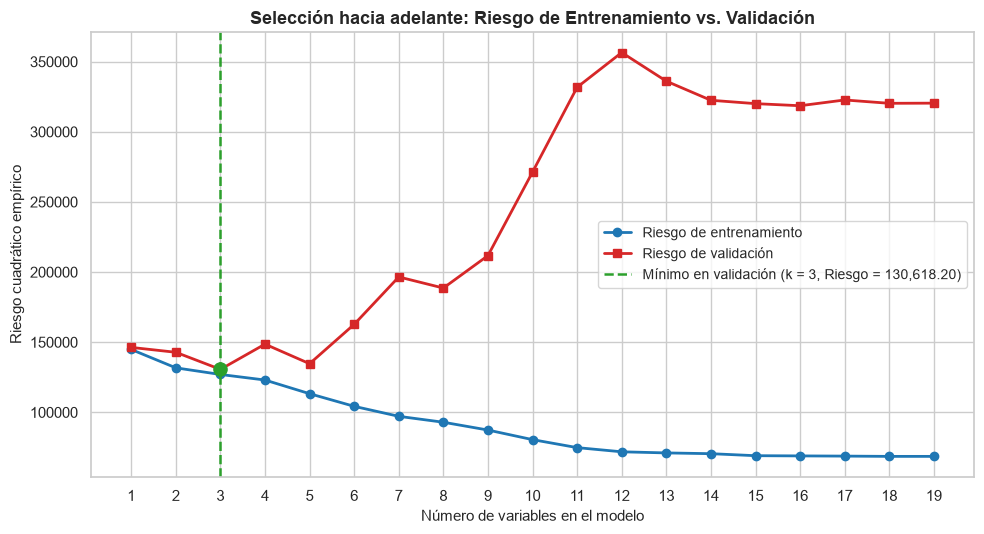

(c) Mejor modelo en validación: k = 3 variables
    Variables utilizadas: ['CRBI', 'Years', 'CRuns']
    Riesgo de entrenamiento: 126,982.3235
    Riesgo de validación:    130,618.1981


In [7]:
idx_mejor_val = df_forward["Riesgo_Validacion"].idxmin()
mejor_fila_forward = df_forward.loc[idx_mejor_val]
k_optimo = int(mejor_fila_forward["Num_Variables"])
riesgo_val_optimo = mejor_fila_forward["Riesgo_Validacion"]

plt.figure(figsize=(10, 5.5))
plt.plot(
    df_forward["Num_Variables"],
    df_forward["Riesgo_Train"],
    marker="o",
    linewidth=2,
    label="Riesgo de entrenamiento",
    color="#1f77b4",
)
plt.plot(
    df_forward["Num_Variables"],
    df_forward["Riesgo_Validacion"],
    marker="s",
    linewidth=2,
    label="Riesgo de validación",
    color="#d62728",
)
plt.axvline(
    x=k_optimo,
    linestyle="--",
    color="#2ca02c",
    linewidth=1.8,
    label=f"Mínimo en validación (k = {k_optimo}, Riesgo = {riesgo_val_optimo:,.2f})",
)
plt.scatter([k_optimo], [riesgo_val_optimo], color="#2ca02c", s=90, zorder=5)

plt.title("Selección hacia adelante: Riesgo de Entrenamiento vs. Validación", fontsize=13, fontweight="bold")
plt.xlabel("Número de variables en el modelo", fontsize=11)
plt.ylabel("Riesgo cuadrático empírico", fontsize=11)
plt.xticks(range(1, 20))
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

vars_forward_opt = mejor_fila_forward["Variables_Modelo"]
print(f"(c) Mejor modelo en validación: k = {k_optimo} variables")
print(f"    Variables utilizadas: {vars_forward_opt}")
print(f"    Riesgo de entrenamiento: {mejor_fila_forward['Riesgo_Train']:,.4f}")
print(f"    Riesgo de validación:    {mejor_fila_forward['Riesgo_Validacion']:,.4f}")

**Respuesta Ejercicio 3 (c):**
- El modelo con menor riesgo de validación en la selección hacia adelante es el que utiliza **$k = 3$ variables**.
- **Variables utilizadas:** `CRBI`, `Years` y `CRuns`.
- **Riesgo de entrenamiento:** `126,982.3235`
- **Riesgo de validación:** `130,618.1981`

A partir de la cuarta variable (`AtBat`), aunque el riesgo de entrenamiento continúa disminuyendo de forma monótona desde `126,982.32` hasta `68,584.82` (en $k=19$), el riesgo de validación comienza a deteriorarse y alcanza picos superiores a `356,000` (en $k=12$), evidenciando el compromiso sesgo-varianza y el sobreajuste por exceso de complejidad.

## Ejercicio 4. Comparación final
Elija uno de los cuatro modelos con base en los riesgos de validación. Después, evalúe todos los modelos en el conjunto de prueba.
- **(a)** Indique qué modelo eligió y con cuál riesgo de validación.
- **(b)** Complete la tabla comparativa con los cuatro modelos.
- **(c)** ¿Qué modelo tiene el menor riesgo de entrenamiento y cuál tiene el menor riesgo de prueba? ¿Coinciden?
- **(d)** ¿El modelo escogido con validación fue el que tuvo menor riesgo de prueba? Responda con los valores de la tabla.

### Evaluación de los 4 modelos en entrenamiento, validación y prueba

In [8]:
eval_completo_final = evaluar_modelo(modelo_completo, todas_las_variables, X_train, y_train, X_val, y_val, X_test, y_test)
eval_corr7_final = evaluar_modelo(modelo_corr7, vars_top7_corr, X_train, y_train, X_val, y_val, X_test, y_test)
eval_pruebas_t_final = evaluar_modelo(modelo_pruebas_t, vars_pruebas_t, X_train, y_train, X_val, y_val, X_test, y_test)

modelo_forward_opt = ajustar_regresion(X_train, y_train, vars_forward_opt)
eval_forward_final = evaluar_modelo(modelo_forward_opt, vars_forward_opt, X_train, y_train, X_val, y_val, X_test, y_test)

tabla_final = pd.DataFrame([
    {
        "Modelo": "Todas las variables",
        "Variables": f"19 ({', '.join(todas_las_variables)})",
        "Riesgo train": eval_completo_final["riesgo_train"],
        "Riesgo validación": eval_completo_final["riesgo_val"],
        "Riesgo prueba": eval_completo_final["riesgo_test"],
    },
    {
        "Modelo": "Mayor correlación",
        "Variables": f"7 ({', '.join(vars_top7_corr)})",
        "Riesgo train": eval_corr7_final["riesgo_train"],
        "Riesgo validación": eval_corr7_final["riesgo_val"],
        "Riesgo prueba": eval_corr7_final["riesgo_test"],
    },
    {
        "Modelo": "Pruebas t",
        "Variables": f"3 ({', '.join(vars_pruebas_t)})",
        "Riesgo train": eval_pruebas_t_final["riesgo_train"],
        "Riesgo validación": eval_pruebas_t_final["riesgo_val"],
        "Riesgo prueba": eval_pruebas_t_final["riesgo_test"],
    },
    {
        "Modelo": "Selección hacia adelante",
        "Variables": f"3 ({', '.join(vars_forward_opt)})",
        "Riesgo train": eval_forward_final["riesgo_train"],
        "Riesgo validación": eval_forward_final["riesgo_val"],
        "Riesgo prueba": eval_forward_final["riesgo_test"],
    },
])

display(tabla_final)

,Modelo,Variables,Riesgo train,Riesgo validación,Riesgo prueba
0,Todas las variables,"19 (AtBat, Hits, HmRun, Runs, RBI, Walks, Year...","68,584.8164","320,423.1919","394,308.6934"
1,Mayor correlación,"7 (CRBI, CRuns, CHmRun, CHits, CAtBat, CWalks,...","115,487.2485","133,035.6122","145,923.2919"
2,Pruebas t,"3 (AtBat, Assists, CWalks)","161,221.3618","140,085.1870","158,772.4728"
3,Selección hacia adelante,"3 (CRBI, Years, CRuns)","126,982.3235","130,618.1981","126,939.5956"


### Respuestas del Ejercicio 4

**(a) Modelo elegido con base en validación:**  
Se elige el modelo de **Selección hacia adelante** de 3 variables (`CRBI`, `Years`, `CRuns`), ya que presenta el menor riesgo de validación entre los cuatro candidatos con un valor de **`130,618.1981`** (frente a `133,035.6122` de Mayor correlación, `140,085.1870` de Pruebas $t$ y `320,423.1919` de Todas las variables).

**(b) Tabla resumen completada:**

| Modelo | Variables | Riesgo train | Riesgo validación | Riesgo prueba |
| :--- | :--- | ---: | ---: | ---: |
| **Todas las variables** | 19 (`AtBat`, `Hits`, `HmRun`, `Runs`, `RBI`, `Walks`, `Years`, `CAtBat`, `CHits`, `CHmRun`, `CRuns`, `CRBI`, `CWalks`, `League`, `Division`, `PutOuts`, `Assists`, `Errors`, `NewLeague`) | 68,584.8164 | 320,423.1919 | 394,308.6934 |
| **Mayor correlación** | 7 (`CRBI`, `CRuns`, `CHmRun`, `CHits`, `CAtBat`, `CWalks`, `Years`) | 115,487.2485 | 133,035.6122 | 145,923.2919 |
| **Pruebas t** | 3 (`AtBat`, `CWalks`, `Assists`) | 161,221.3618 | 140,085.1870 | 158,772.4728 |
| **Selección hacia adelante** | 3 (`CRBI`, `Years`, `CRuns`) | 126,982.3235 | **130,618.1981** | **126,939.5956** |

**(c) Menor riesgo de entrenamiento vs. menor riesgo de prueba:**  
- El modelo con el **menor riesgo de entrenamiento** es el de **Todas las variables** (`68,584.8164`).
- El modelo con el **menor riesgo de prueba** es el de **Selección hacia adelante** (`126,939.5956`).
- **No coinciden.** De hecho, el modelo con todas las variables es el que tiene el **peor** riesgo en prueba (`394,308.6934`), pues memoriza el ruido de las 50 observaciones de entrenamiento y pierde capacidad de generalización fuera de la muestra.

**(d) ¿El modelo escogido con validación fue el que tuvo menor riesgo de prueba?**  
**Sí.** El modelo de **Selección hacia adelante** (`CRBI`, `Years`, `CRuns`), escogido por alcanzar el menor riesgo de validación (`130,618.1981`), también obtuvo el menor riesgo en el conjunto de prueba con **`126,939.5956`**, superando al modelo de Mayor correlación (`145,923.2919`), al de Pruebas $t$ (`158,772.4728`) y al modelo completo (`394,308.6934`).

## Exportar resultados

In [9]:

# Carpeta resutls
ruta_results = Path("../results").resolve()
ruta_results.mkdir(parents=True, exist_ok=True)

# 2. Tablas
df_correlaciones.to_csv(ruta_results / "01_correlaciones_pearson.csv", index=False)
df_pruebas_t.to_csv(ruta_results / "02_pruebas_t_modelo_completo.csv", index=False)
df_forward[["Num_Variables", "Variable_Agregada", "Riesgo_Train", "Riesgo_Validacion"]].to_csv(
    ruta_results / "03_tabla_seleccion_adelante.csv", index=False
)
tabla_final.to_csv(ruta_results / "04_comparacion_modelos_final.csv", index=False)

# 3. Graficas
plt.figure(figsize=(10, 5.5), dpi=300)
plt.plot(
    df_forward["Num_Variables"],
    df_forward["Riesgo_Train"],
    marker="o",
    linewidth=2,
    label="Riesgo de entrenamiento",
    color="#1f77b4",
)
plt.plot(
    df_forward["Num_Variables"],
    df_forward["Riesgo_Validacion"],
    marker="s",
    linewidth=2,
    label="Riesgo de validación",
    color="#d62728",
)
plt.axvline(
    x=k_optimo,
    linestyle="--",
    color="#2ca02c",
    linewidth=1.8,
    label=f"Mínimo en validación (k = {k_optimo})",
)
plt.scatter([k_optimo], [riesgo_val_optimo], color="#2ca02c", s=90, zorder=5)

plt.title("Selección hacia adelante: Riesgo de Entrenamiento vs. Validación", fontsize=13, fontweight="bold")
plt.xlabel("Número de variables en el modelo", fontsize=11)
plt.ylabel("Riesgo cuadrático empírico", fontsize=11)
plt.xticks(range(1, 20))
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

# Guardar la figura en la carpeta
ruta_grafica = ruta_results / "curva_riesgos_forward_selection.png"
plt.savefig(ruta_grafica, dpi=300, bbox_inches="tight")
plt.close()

print(f"Archivos exportados exitosamente en: {ruta_results}")

Archivos exportados exitosamente en: C:\Users\Medin\Downloads\Quinta_Lista_Ejercicios\results
